<a href="https://colab.research.google.com/github/sandeep0608/LeNet-from-scratch/blob/main/LeNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cuda


In [2]:
transform = transforms.ToTensor()   # turns each image into numbers, scaled 0–1

train_set = datasets.MNIST(root="./data", train=True,  download=True, transform=transform)
test_set  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_set,  batch_size=1000, shuffle=False)

print("Training images:", len(train_set))
print("Test images:", len(test_set))

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 491kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.60MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.5MB/s]

Training images: 60000
Test images: 10000


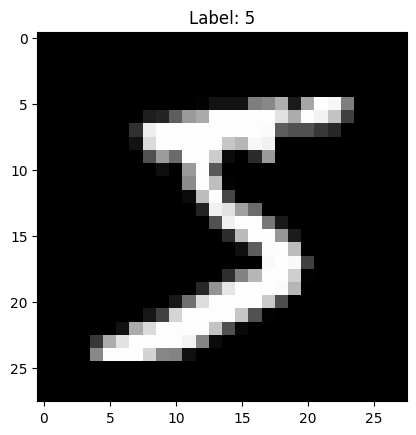

Image shape: torch.Size([1, 28, 28])


In [3]:
import matplotlib.pyplot as plt

image, label = train_set[0]        # grab the first image and its correct answer
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Label: {label}")
plt.show()

print("Image shape:", image.shape)

In [4]:
class LeNet5(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # TODO: define the layers here. Hints:
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5, padding=2)
        self.pool  = nn.MaxPool2d(2, 2)          # one pool, reused twice
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.fc1   = nn.Linear(16*5*5, 120)      # 16*5*5 = 400
        self.fc2   = nn.Linear(120, 84)
        self.fc3   = nn.Linear(84, num_classes)
        pass  # <-- replace this with your layer definitions

    def forward(self, x):
        # TODO: connect them in order. The pattern is:
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)                  # flatten, keeping the batch
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)                          # no activation on the last one
        return x
        pass  # <-- replace this with your forward pass

model = LeNet5().to(device)
print(model)

LeNet5(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)


In [5]:
images, labels = next(iter(train_loader))   # grab one batch of 64 images
images = images.to(device)

outputs = model(images)                      # run them through your forward pass
print("Input shape: ", images.shape)
print("Output shape:", outputs.shape)

Input shape:  torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])


In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

for epoch in range(5):
    model.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()                 # 1. clear old gradients
        outputs = model(images)               # 2. forward pass
        loss = criterion(outputs, labels)     # 3. how wrong was it?
        loss.backward()                       # 4. compute the nudges
        optimizer.step()                      # 5. apply the nudges

    print(f"Epoch {epoch+1} done — last loss: {loss.item():.4f}")

Epoch 1 done — last loss: 0.1827
Epoch 2 done — last loss: 0.0123
Epoch 3 done — last loss: 0.0110
Epoch 4 done — last loss: 0.0924
Epoch 5 done — last loss: 0.0109


In [7]:
model.eval()                         # switch to evaluation mode
correct = total = 0
with torch.no_grad():                # no learning here, just checking
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        predicted = outputs.argmax(1)             # the digit with the highest score
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

print(f"Test accuracy: {100 * correct / total:.2f}%")

Test accuracy: 98.49%


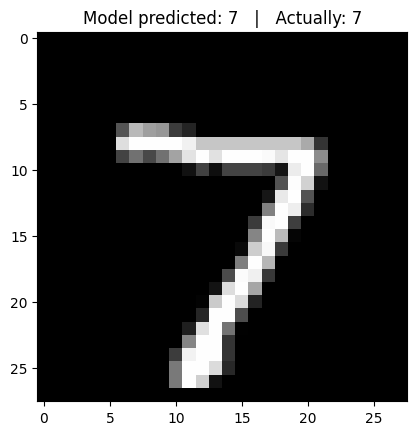

In [8]:
import matplotlib.pyplot as plt

image, label = test_set[0]                      # a test image it never trained on
model.eval()
with torch.no_grad():
    output = model(image.unsqueeze(0).to(device))   # add a batch dimension, run it
    prediction = output.argmax(1).item()

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Model predicted: {prediction}   |   Actually: {label}")
plt.show()

In [9]:
torch.save(model.state_dict(), "lenet5_mnist.pth")
print("Saved! Download it from the file panel on the left (folder icon).")

Saved! Download it from the file panel on the left (folder icon).


In [10]:
image, label = train_set[0]          # the "5" you saw earlier
grid = (image.squeeze().numpy() * 100).astype(int)   # scale to 0–100 for readability

import numpy as np
np.set_printoptions(linewidth=200)
print("This is the digit:", label)
print(grid)

This is the digit: 5
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   1   7   7   7  49  53  68  10  65 100  96  49   0   0   0   0]
 [  0   0   0   0   0   0   0   0  11  14  36  60  66  99  99  99  99  99  88  67  99  94  76  25   0   0   0   0]
 [  0   0   0   0   0   0   0  19  93  99  99  99  99  99  99  99  99  98  36  32  32  21  15   0   0   0   0   0]
 [  0   0   0   0   0   0   0   7  85  99  99  99  99  99  

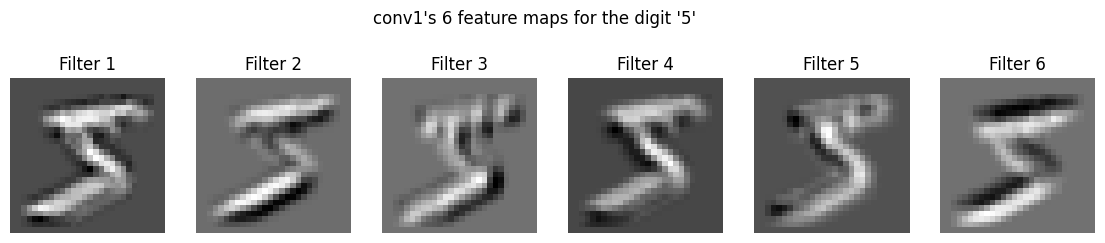

In [11]:
import matplotlib.pyplot as plt

image, label = train_set[0]                      # the "5"
model.eval()
with torch.no_grad():
    maps = model.conv1(image.unsqueeze(0).to(device))   # just the conv1 output: 6 maps

maps = maps.squeeze().cpu()
fig, axes = plt.subplots(1, 6, figsize=(14, 3))
for i in range(6):
    axes[i].imshow(maps[i], cmap="gray")
    axes[i].set_title(f"Filter {i+1}")
    axes[i].axis("off")
plt.suptitle(f"conv1's 6 feature maps for the digit '{label}'")
plt.show()

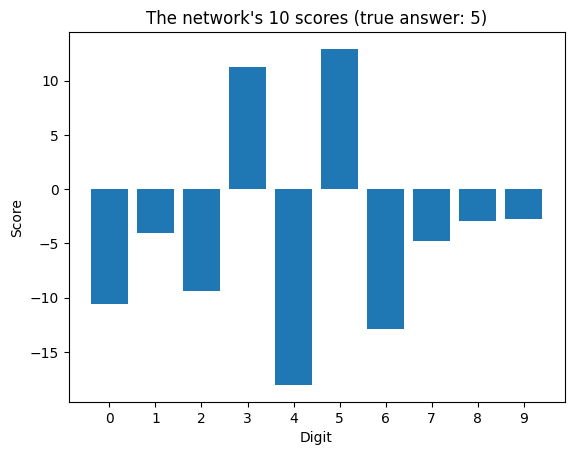

Scores: [-10.6, -4.0, -9.3, 11.2, -18.0, 12.9, -12.9, -4.8, -3.0, -2.8]
Winner (argmax): 5


In [12]:
import matplotlib.pyplot as plt

image, label = train_set[0]                       # the "5"
model.eval()
with torch.no_grad():
    scores = model(image.unsqueeze(0).to(device)).squeeze().cpu()

plt.bar(range(10), scores)
plt.xticks(range(10))
plt.xlabel("Digit")
plt.ylabel("Score")
plt.title(f"The network's 10 scores (true answer: {label})")
plt.show()

print("Scores:", [round(s.item(), 1) for s in scores])
print("Winner (argmax):", scores.argmax().item())

Epoch 1 done
Epoch 2 done
Epoch 3 done
Epoch 4 done
Epoch 5 done


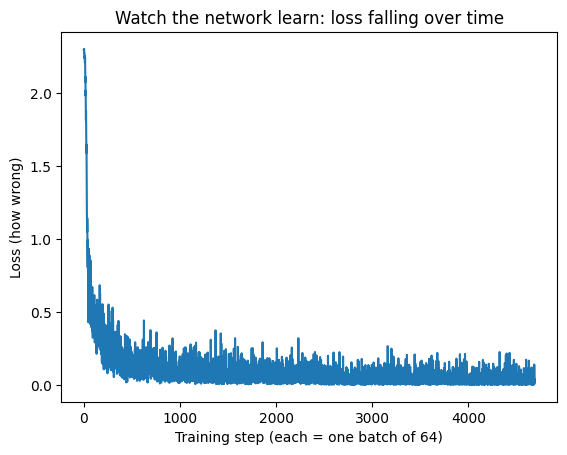

In [14]:
import matplotlib.pyplot as plt

model = LeNet5().to(device)                        # fresh, random model
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

losses = []                                        # record wrongness at every step
for epoch in range(5):
    model.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())                 # save it
    print(f"Epoch {epoch+1} done")

plt.plot(losses)
plt.xlabel("Training step (each = one batch of 64)")
plt.ylabel("Loss (how wrong)")
plt.title("Watch the network learn: loss falling over time")
plt.show()